# Estimating the monthly revenue of informal businesses in Nigeria

**Mission link.** My mission is to build practical technology that makes complex systems work better for people
across Africa, and to create more accessible opportunities for businesses. Most small Nigerian businesses (kiosks,
tailors, food sellers, repair shops) have no bank statements or audited accounts, so lenders cannot tell how much
they could repay, and they get no credit at all. I have seen this problem first-hand while building a MoMo-based
credit scoring tool.

**Use case.** A digital lender or microfinance officer fills in 12 facts that any business owner can answer in
two minutes: state, sector, urban or rural, number of workers, age of the business, the owner's education, and so
on. The model estimates the business's **monthly revenue per worker** (in PPP US dollars). The lender then uses that
estimate to size a loan the business can realistically repay, instead of rejecting it for having no paperwork.

**Dataset.** World Bank LSMS, *Household Business Indicators for Sub-Saharan Africa 2014-2024*
(AFR_2014-2024_LSMS-HBI_v01_M, by Jiapei Zhang, Ivette Contreras and Amparo Palacios-Lopez, World Bank Group),
downloaded on 18 November 2026 from <https://microdata.worldbank.org/index.php/catalog/8591>. For Nigeria the
rows come from the General Household Survey Panel run by the National Bureau of Statistics and the World Bank
(wave 4 = 2018/19, wave 5 = 2023/24). Revenue is converted to PPP-adjusted US dollars, which adjust for price
levels so that amounts are comparable across countries. PPP does not remove inflation between the two rounds.

*The licence does not allow the data to be redistributed, so the CSV is not in this repository. To rerun the
notebook, download `LSMS_HBI_BUSINESS.csv` from the link above into `linear_regression/data/`.*

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

SEED = 42                                   # same seed everywhere -> same numbers on every run
pd.set_option("display.max_columns", 40)

# chart colours: blue = train, orange = test, grey = text
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})
def left_title(ax):
    ax.title.set_ha("left"); ax.title.set_x(0)

## 1. Load the data and keep Nigeria
The file covers five countries. I keep only Nigeria, so the model learns one economy, one currency conversion
and one survey design.

In [2]:
DATA_FILE = Path("data") / "LSMS_HBI_BUSINESS.csv"
# The World Bank licence does not allow the data to be shared, so it is NOT in the GitHub repo.
# Download it from https://microdata.worldbank.org/index.php/catalog/8591 and place it in data/.
raw = pd.read_csv(DATA_FILE, low_memory=False)
print(f"All countries: {raw.shape[0]:,} businesses x {raw.shape[1]} columns")
print(raw["country"].value_counts().to_string())

ng = raw[raw["country"] == "Nigeria"].copy()
print(f"\nNigeria: {len(ng):,} businesses")
print(ng["wave"].value_counts().sort_index().rename({4.0: "wave 4 (2018/19)", 5.0: "wave 5 (2023/24)"}).to_string())

All countries: 20,656 businesses x 43 columns
country
Nigeria     7355
Tanzania    4600
Ethiopia    3286
Malawi      3270
Uganda      2145

Nigeria: 7,355 businesses
wave
wave 4 (2018/19)    3919
wave 5 (2023/24)    3436


## 2. Understand the target before choosing anything
The target is `revenue_worker_ppp`. The documentation (Indicator 36) defines it as the business's total
**monthly** revenue divided by its total number of workers, in PPP US dollars.

In [3]:
target = ng["revenue_worker_ppp"]
print(f"Missing target: {target.isna().sum()} rows")
print(f"Median {target.median():,.0f} | mean {target.mean():,.0f} | max {target.max():,.0f} PPP $ per worker per month")
print(f"Skew of revenue: {target.skew():.1f}   ->   skew of log(1 + revenue): {np.log1p(target).skew():.2f}")
print("\nMedian by survey round:", ng.groupby("wave")["revenue_worker_ppp"].median().round(0).to_dict())

print("\nColumns that are completely empty for Nigeria:", [c for c in ng.columns if ng[c].isna().all()])
miss = (ng.isna().mean() * 100).round(1)
print("Partly missing (%):", miss[(miss > 0) & (miss < 100)].to_dict())

Missing target: 72 rows
Median 975 | mean 2,356 | max 502,170 PPP $ per worker per month
Skew of revenue: 35.2   ->   skew of log(1 + revenue): -0.02

Median by survey round: {4.0: 772.0, 5.0: 1365.0}

Columns that are completely empty for Nigeria: ['owner_age', 'ngo_start', 'con_power_outage', 'con_infra_wt']
Partly missing (%): {'hhweight': 0.4, 'hhbusiness_age': 10.4, 'owner_educ': 16.9, 'owner_agecat': 0.3, 'revenue_worker_ppp': 1.0, 'cost_ppp': 47.4, 'profit_margin': 2.1, 'con_demand': 0.1, 'con_finance': 0.1, 'con_electricity': 0.1, 'con_internet': 0.1, 'con_crime': 0.1, 'con_reg_tax': 0.1}


**What this told me and what I decided:**
* Revenue is extremely skewed (skew **35.2**). The median business makes **975** PPP $ per worker per month but the
  biggest makes **502,170**. On the raw scale a handful of giant businesses would dominate the MSE, so the model
  predicts **log(1 + revenue)**, which has a skew of **-0.02** (almost perfectly symmetric). The API converts the
  prediction back to dollars.
* The median almost doubles between rounds, from **772** (2018/19) to **1,365** (2023/24). The two rounds are five
  years apart and use different PPP years, so the survey year has to be an input.
* Four columns are **100% empty** for Nigeria and two inputs I want are partly missing: business age (10.4%) and
  owner education (16.9%). I fill those two with the training median inside the pipeline.
* `profit_margin` is calculated from revenue ((revenue − cost) ÷ revenue), so it would leak the answer and is dropped.
  `cost_ppp` is missing for 47.4% of Nigerian rows, too many to fill honestly, so it is dropped too.

## 3. Clean the data
I drop the 72 businesses with no revenue (nothing to learn from) and one exact duplicate row. I also turn the
region text "NG: Kano" into a plain state name and the wave number into the year the round ended (2019 or 2024).

In [4]:
df = ng.dropna(subset=["revenue_worker_ppp"]).copy()
steps = [("Nigeria rows", len(ng)), ("drop rows with no revenue", len(df))]

df = df[~df.drop(columns=["hhbusiness_id"]).duplicated()]
steps.append(("drop exact duplicate rows", len(df)))

df["state"] = df["region"].str.replace("NG: ", "", regex=False)    # "NG: Kano" -> "Kano"
df["survey_year"] = df["wave"].map({4.0: 2019, 5.0: 2024}).astype(int)  # year each round ended
pd.DataFrame(steps, columns=["step", "rows left"])

,step,rows left
0,Nigeria rows,7355
1,drop rows with no revenue,7283
2,drop exact duplicate rows,7282


## 4. Feature engineering: the 12 inputs
Each input is something a loan officer can ask the owner directly. The table below shows their ranges. For
example, the median business has 1 worker and is 6 years old, and the owner has 10 years of education.
`owner_age_group` is the survey's own age bands (1 = 15-24, 2 = 25-34, 3 = 35-44, 4 = 45-54, 5 = 55-64, 6 = 65+).

In [5]:
RENAME = {
    "state": "state",
    "sector": "sector",
    "urban": "urban",
    "survey_year": "survey_year",
    "total_workers": "total_workers",
    "hhbusiness_age": "business_age",
    "owner_educ": "owner_education_years",
    "owner_agecat": "owner_age_group",
    "owner_female": "owner_female",
    "sep_premises": "separate_premises",
    "sell_firms_state": "sells_to_firms_or_govt",
    "con_finance": "credit_difficulty",
    "revenue_worker_ppp": "revenue_per_worker",
}
data = df[list(RENAME) + ["hhid"]].rename(columns=RENAME).reset_index(drop=True)

TARGET = "revenue_per_worker"
CATEGORICAL = ["state", "sector", "urban"]
NUMERIC = ["survey_year", "total_workers", "business_age", "owner_education_years", "owner_age_group",
           "owner_female", "separate_premises", "sells_to_firms_or_govt", "credit_difficulty"]
FEATURES = NUMERIC + CATEGORICAL
data["log_revenue"] = np.log1p(data[TARGET])          # the model learns this; the API converts back

print(f"Model table: {len(data):,} rows | {len(FEATURES)} inputs ({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print(f"Kept 12 of the 43 original columns as inputs\n")
data[FEATURES + [TARGET]].describe(include="all").T

Model table: 7,282 rows | 12 inputs (9 numeric, 3 categorical)
Kept 12 of the 43 original columns as inputs



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survey_year,7282.0,NaN,NaN,NaN,2021.344136,2.495308,2019.0,2019.0,2019.0,2024.0,2024.0
total_workers,7282.0,NaN,NaN,NaN,1.553694,1.841901,1.0,1.0,1.0,1.0,56.0
business_age,6527.0,NaN,NaN,NaN,8.542056,7.833721,1.0,3.0,6.0,10.0,77.0
owner_education_years,6047.0,NaN,NaN,NaN,8.677691,4.912378,0.0,6.0,10.0,12.0,18.0
owner_age_group,7260.0,NaN,NaN,NaN,3.257025,1.349534,1.0,2.0,3.0,4.0,6.0
owner_female,7282.0,NaN,NaN,NaN,0.544905,0.498014,0.0,0.0,1.0,1.0,1.0
separate_premises,7282.0,NaN,NaN,NaN,0.380527,0.48555,0.0,0.0,0.0,1.0,1.0
sells_to_firms_or_govt,7282.0,NaN,NaN,NaN,0.116863,0.32128,0.0,0.0,0.0,0.0,1.0
credit_difficulty,7278.0,NaN,NaN,NaN,0.183842,0.387382,0.0,0.0,0.0,0.0,1.0
state,7282,37,Kaduna,522,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Columns I dropped and why.** I kept 12 of the 43 columns. The critical drop is `profit_margin`, which is
built from revenue (leakage); `cost_ppp` goes because almost half of it is missing. The last row explains the rest: in a first random-forest check, each of those flags added
less than 2.5% importance, and the mobile app needs one text field per input, so I kept the form to 12 fields.

In [6]:
pd.DataFrame([
    ("profit_margin", "Leakage: (revenue - cost) / revenue is built from the target"),
    ("cost_ppp", "47.4% missing for Nigeria - too much to fill honestly"),
    ("owner_age, ngo_start, con_power_outage, con_infra_wt", "100% empty for Nigeria"),
    ("firm_size, size_1worker, size_2to4, size_5plus", "Copies of total_workers in another form"),
    ("nonhh_workers", "Part of total_workers; keeping both double counts the same signal"),
    ("country", "Always Nigeria after filtering"),
    ("hhid, hhbusiness_id", "Identifiers. hhid is kept aside only to split by household"),
    ("hhweight", "Survey weight for national averages, not a property of the business"),
    ("region", "Replaced by the cleaner 'state' column"),
    ("water, electricity, generator, tax_id, formal and the start-up funding / difficulty flags",
     "Each added < 2.5% importance in a first random-forest check; dropped to keep the app to 12 fields"),
], columns=["dropped", "reason"])

,dropped,reason
0,profit_margin,Leakage: (revenue - cost) / revenue is built f...
1,cost_ppp,47.4% missing for Nigeria - too much to fill h...
2,"owner_age, ngo_start, con_power_outage, con_in...",100% empty for Nigeria
3,"firm_size, size_1worker, size_2to4, size_5plus",Copies of total_workers in another form
4,nonhh_workers,Part of total_workers; keeping both double cou...
5,country,Always Nigeria after filtering
6,"hhid, hhbusiness_id",Identifiers. hhid is kept aside only to split ...
7,hhweight,"Survey weight for national averages, not a pro..."
8,region,Replaced by the cleaner 'state' column
9,"water, electricity, generator, tax_id, formal ...",Each added < 2.5% importance in a first random...


**Converting categorical columns to numbers.** `state` (37 values), `sector` (4) and `urban` (2) are text. A
`OneHotEncoder` inside the pipeline turns each one into 0/1 columns, as the table below shows, so the API can
receive plain text like `"Kano"` and the saved model encodes it itself. The yes/no questions (female owner,
separate premises, sells to firms, credit difficulty) are already 0/1 numbers in the data.

In [7]:
print("sector:", data["sector"].value_counts().to_dict())
print("urban:", data["urban"].value_counts().to_dict())
print(f"state: {data['state'].nunique()} states, e.g. {data['state'].value_counts().head(5).to_dict()}")
pd.get_dummies(data[["sector", "urban"]].head(5), dtype=int)       # what one-hot encoding produces

sector: {'Services': 5736, 'Manufacturing': 1357, 'Agriculture': 113, 'Other': 76}
urban: {'Urban': 4534, 'Rural': 2748}
state: 37 states, e.g. {'Kaduna': 522, 'Kano': 402, 'Akwa Ibom': 374, 'Abia': 345, 'Katsina': 340}


,sector_Manufacturing,sector_Services,urban_Rural,urban_Urban
0,0,1,1,0
1,0,1,1,0
2,0,1,0,1
3,1,0,0,1
4,0,1,0,1


## 5. Visualisations that shaped the model
### 5.1 Correlation heatmap

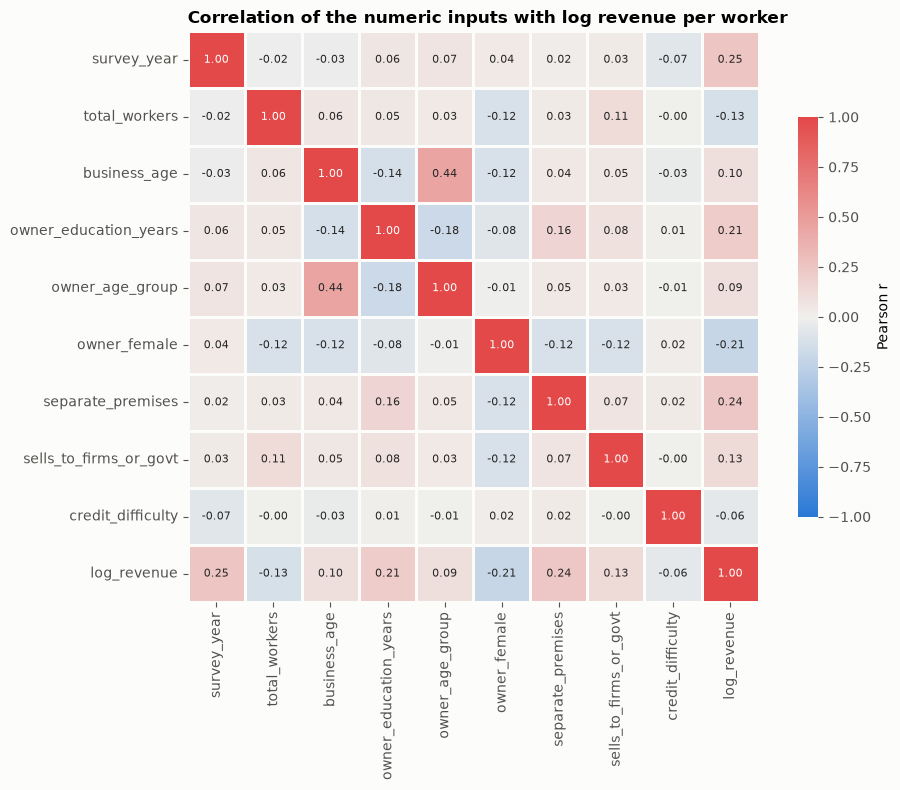

survey_year               0.255
separate_premises         0.236
owner_female             -0.208
owner_education_years     0.206
total_workers            -0.132
sells_to_firms_or_govt    0.128
business_age              0.100
owner_age_group           0.094
credit_difficulty        -0.060
Name: log_revenue, dtype: float64

In [8]:
corr = data[NUMERIC + ["log_revenue"]].corr()
diverging = LinearSegmentedColormap.from_list("blue_grey_red", ["#2a78d6", "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap=diverging, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=2, linecolor="#fcfcfb", square=True, cbar_kws={"shrink": 0.7, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation of the numeric inputs with log revenue per worker"); left_title(ax); ax.grid(False)
plt.tight_layout(); plt.show()
corr["log_revenue"].drop("log_revenue").sort_values(key=abs, ascending=False).round(3)

**What it shows.** No input has a strong straight-line link with log revenue. The strongest are `survey_year`
(**0.26**), `separate_premises` (**0.24**), `owner_education_years` (**0.21**) and `owner_female` (**−0.21**: on
average, businesses run by women report lower revenue per worker). `total_workers` is slightly *negative*
(−0.13): revenue is divided by the number of workers, so a bigger team doesn't mean more revenue per head. The
inputs are only weakly correlated with each other. The highest pair is business age and owner age group (0.44),
which makes sense because older owners tend to run older businesses, so no two inputs repeat the same signal.

**What I decided because of it.** Weak correlations mean a straight line will explain only part of the variation,
so I expect the tree models to matter. Because the inputs barely overlap, I kept all nine numeric ones. The
heatmap also picks the feature for the before/after scatter plots in section 11: `survey_year`.

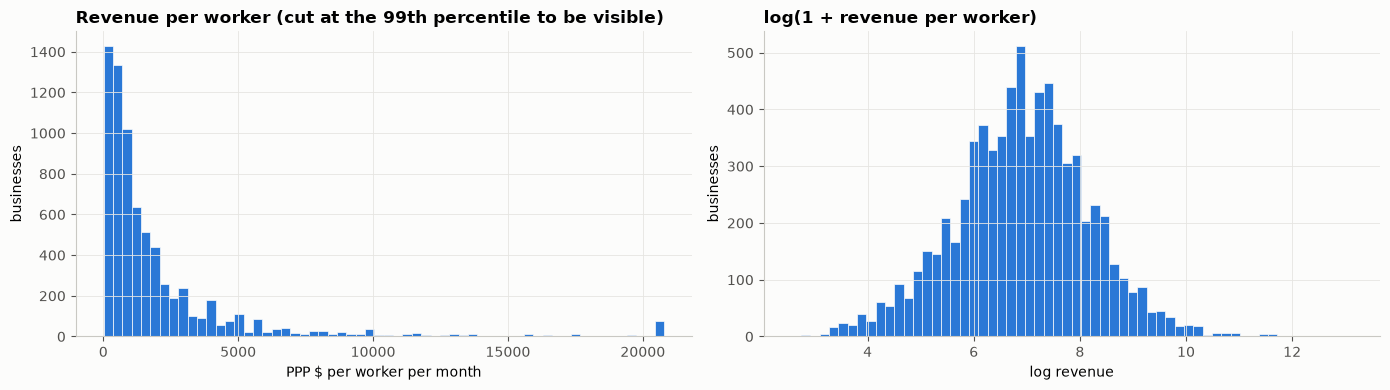

Top 1% of businesses earn above 20,785 PPP $ per worker; the largest is 502,170


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data[TARGET].clip(upper=data[TARGET].quantile(0.99)), bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set(title="Revenue per worker (cut at the 99th percentile to be visible)", xlabel="PPP $ per worker per month", ylabel="businesses")
axes[1].hist(data["log_revenue"], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="log(1 + revenue per worker)", xlabel="log revenue", ylabel="businesses")
for a in axes: left_title(a)
plt.tight_layout(); plt.show()
print(f"Top 1% of businesses earn above {data[TARGET].quantile(0.99):,.0f} PPP $ per worker; the largest is {data[TARGET].max():,.0f}")

**What it shows.** On the left, revenue piles up near zero with a long tail, and that is *after* cutting the top 1%
(businesses above 20,785 PPP $ per worker). On the right, the log version forms a near-normal bell centred
around 7 (about e⁷ ≈ 1,100 PPP $).

**What I decided because of it.** I train every model on log revenue. Each one then works on percentage
differences instead of being pulled around by a few huge businesses, and the MSE becomes "squared error in log
units". I keep the big businesses in the data rather than deleting them, because a lender will meet them too.

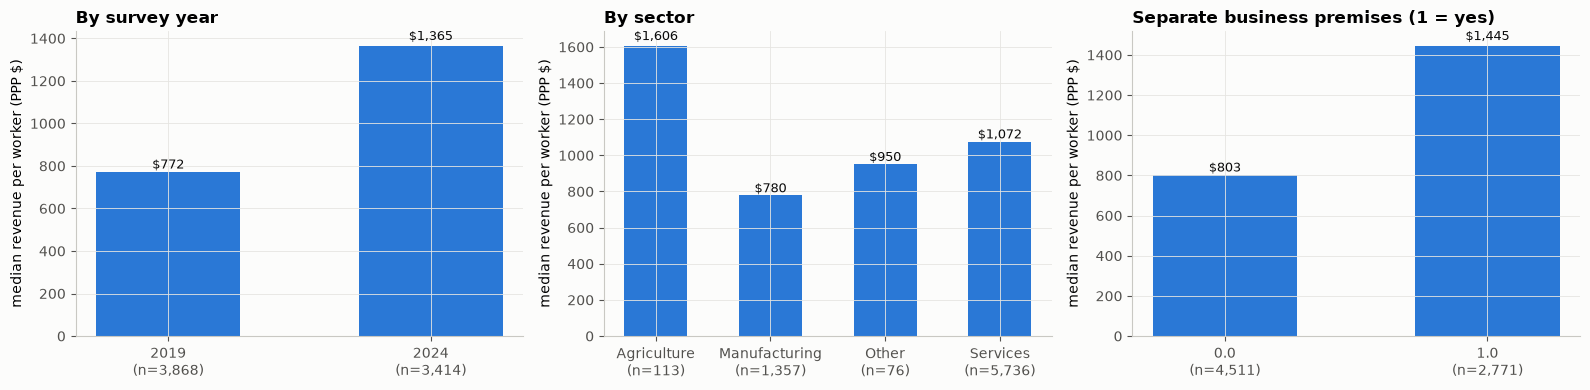

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in [(axes[0], "survey_year", "By survey year"), (axes[1], "sector", "By sector"),
                       (axes[2], "separate_premises", "Separate business premises (1 = yes)")]:
    g = data.groupby(col)[TARGET].agg(["median", "count"])
    labels = [f"{i}\n(n={c:,})" for i, c in zip(g.index, g["count"])]
    ax.bar(labels, g["median"], color=BLUE, width=0.55)
    for i, v in enumerate(g["median"]): ax.text(i, v * 1.02, f"${v:,.0f}", ha="center", color=INK, fontsize=9)
    ax.set(title=title, ylabel="median revenue per worker (PPP $)"); left_title(ax)
plt.tight_layout(); plt.show()

**What it shows.** The median business earned **$772** per worker in 2019 and **$1,365** in 2024. Businesses with
their own premises earn **$1,445** against **$803** for those without. By sector, agriculture has the highest
median (**$1,606**) but only **113** businesses, and services is by far the largest group (**5,736**).

**What I decided because of it.** Survey year and separate premises clearly shift revenue, so both stay in.
Agriculture (113) and Other (76) are small groups, so I expect predictions for them to be the least reliable. I
keep them so the app accepts every real sector.

## 6. Train / test split by household (important for this dataset)
This is a **panel survey**: 1,863 of the 3,579 Nigerian households were interviewed in both rounds, and many run
more than one business. With a random split, the same household could appear in train (2019) and in test (2024),
so the test score would partly measure memory, not prediction. I therefore split with **`GroupShuffleSplit` on the
household ID**, so every household is entirely in one side. The output confirms there are **0** households in both
train and test.

Order of the splits:
1. 5% of households (**391 rows**) are held back as *new data* for the `/retrain` endpoint and saved to a local
   file that is not in the repository.
2. Of the rest, 80% of households go to train (**5,487 rows**) and 20% to test (**1,404 rows**).
3. Inside train, 20% of households form a validation set (**1,059 rows**). Every hyperparameter is chosen on
   validation, so the test set is used **once**, in the final comparison.

In [11]:
# 1) hold back ~5% of HOUSEHOLDS as "new data" for the /retrain demo; no model sees them here
gss = GroupShuffleSplit(n_splits=1, test_size=0.05, random_state=SEED)
keep_idx, new_idx = next(gss.split(data, groups=data["hhid"]))
new_arrivals, model_data = data.iloc[new_idx], data.iloc[keep_idx].reset_index(drop=True)
new_arrivals[FEATURES + [TARGET]].to_csv(Path("data") / "new_businesses_for_retraining.csv", index=False)  # stays local (gitignored)

# 2) train / test split BY HOUSEHOLD: a household is either fully in train or fully in test
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(model_data, groups=model_data["hhid"]))
train, test = model_data.iloc[tr_idx], model_data.iloc[te_idx]

# 3) validation slice from TRAIN only, also by household, for choosing hyperparameters
tr2, val = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(train, groups=train["hhid"]))
fit_part, val_part = train.iloc[tr2], train.iloc[val]

X_train, y_train = train[FEATURES], train["log_revenue"]
X_test, y_test = test[FEATURES], test["log_revenue"]
X_fit, y_fit, X_val, y_val = fit_part[FEATURES], fit_part["log_revenue"], val_part[FEATURES], val_part["log_revenue"]

overlap = set(train["hhid"]) & set(test["hhid"])
print(f"new-data hold-out: {len(new_arrivals)} rows | train {len(train):,} (fit {len(fit_part):,} + validation {len(val_part):,}) | test {len(test):,}")
print(f"households in both train and test: {len(overlap)}")

new-data hold-out: 391 rows | train 5,487 (fit 4,428 + validation 1,059) | test 1,404
households in both train and test: 0


### Missing values, scaling and one-hot encoding, fitted on the training set only
One `ColumnTransformer` does all the preprocessing. It fills missing numbers with the **training** median,
standardises the numeric columns, and one-hot encodes the three text columns. It is `.fit()` on `X_train` only;
the test rows are only `.transform()`ed.

In [12]:
def make_preprocessor():
    """Same preprocessing for every model, saved inside the model file."""
    numeric = Pipeline([("fill_missing", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return ColumnTransformer([
        ("num", numeric, NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])

prep = make_preprocessor().fit(X_train)                    # learns medians, means and std from TRAIN only
Xtr_s, Xte_s = prep.transform(X_train), prep.transform(X_test)
names = prep.get_feature_names_out()
print(f"{X_train.shape[1]} raw inputs -> {Xtr_s.shape[1]} model columns after one-hot encoding")
pd.DataFrame({"train mean": Xtr_s.mean(0)[:len(NUMERIC)], "train std": Xtr_s.std(0)[:len(NUMERIC)],
              "test mean": Xte_s.mean(0)[:len(NUMERIC)]}, index=NUMERIC).round(3)

12 raw inputs -> 52 model columns after one-hot encoding


,train mean,train std,test mean
survey_year,-0.0,1.0,-0.003
total_workers,0.0,1.0,0.058
business_age,0.0,1.0,-0.046
owner_education_years,-0.0,1.0,0.040
owner_age_group,-0.0,1.0,-0.034
owner_female,0.0,1.0,-0.001
separate_premises,0.0,1.0,0.011
sells_to_firms_or_govt,0.0,1.0,0.037
credit_difficulty,0.0,1.0,-0.090


The 12 inputs become **52 model columns** (37 states + 4 sectors + 2 area types + 9 numeric). Every scaled training
column has mean 0 and standard deviation 1. The test means are close to 0 but not exactly 0 (for example −0.090 for
`credit_difficulty`), which is the sign that the scaler never saw the test rows.

## 7. Model 1: linear regression by gradient descent (`SGDRegressor`)
This is the main model. I train it one epoch at a time with `partial_fit`, reshuffle the rows each epoch, and
record train and validation MSE after every epoch. I tuned:
* **learning rate** `eta0`: 0.0001, 0.001, 0.01, 0.05 (constant schedule, so the effect of each value is visible)
* **L2 regularisation** `alpha`: 0.0001 to 1.0
* **epochs**: up to 60, keeping the epoch with the lowest validation MSE

In [13]:
prep_fit = make_preprocessor().fit(X_fit)
Xf, Xv = prep_fit.transform(X_fit), prep_fit.transform(X_val)
yf, yv = y_fit.to_numpy(), y_val.to_numpy()

def train_sgd(Xa, ya, Xb, yb, eta0, alpha, epochs, seed=SEED):
    """SGDRegressor trained one epoch at a time with partial_fit; MSE recorded after every epoch."""
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, penalty="l2", alpha=alpha, random_state=seed)
    rng = np.random.default_rng(seed)
    hist_a, hist_b = [np.mean(ya ** 2)], [np.mean(yb ** 2)]     # epoch 0: weights are zero, prediction = 0
    for _ in range(epochs):
        order = rng.permutation(len(Xa))                          # new random order every epoch
        sgd.partial_fit(Xa[order], ya[order])
        hist_a.append(mean_squared_error(ya, sgd.predict(Xa)))
        hist_b.append(mean_squared_error(yb, sgd.predict(Xb)))
    return sgd, np.array(hist_a), np.array(hist_b)

rows = []
for eta0 in [0.0001, 0.001, 0.01, 0.05]:
    for alpha in [0.0001, 0.001, 0.01, 0.1, 1.0]:
        _, _, vh = train_sgd(Xf, yf, Xv, yv, eta0, alpha, epochs=60)
        rows.append({"eta0": eta0, "alpha": alpha, "val MSE @ epoch 1": vh[1], "val MSE @ epoch 60": vh[-1],
                     "best epoch": int(vh[1:].argmin()) + 1, "best val MSE": vh[1:].min()})
sgd_grid = pd.DataFrame(rows).sort_values("best val MSE").reset_index(drop=True)
sgd_grid.round({"val MSE @ epoch 1": 4, "val MSE @ epoch 60": 4, "best val MSE": 4})

,eta0,alpha,val MSE @ epoch 1,val MSE @ epoch 60,best epoch,best val MSE
0,0.0010,0.0010,1.3922,1.1567,50,1.1454
1,0.0010,0.0001,1.3924,1.1576,22,1.1455
2,0.0010,0.0100,1.3912,1.1598,50,1.1486
3,0.0100,0.0010,1.2372,1.2199,31,1.1657
4,0.0100,0.0001,1.2367,1.2200,31,1.1667
5,0.0100,0.0100,1.2429,1.2292,31,1.1691
6,0.0010,0.1000,1.3976,1.2117,50,1.1996
7,0.0001,0.0001,8.4304,1.2020,60,1.2020
8,0.0001,0.0010,8.4324,1.2021,60,1.2021
9,0.0001,0.0100,8.4521,1.2041,60,1.2041


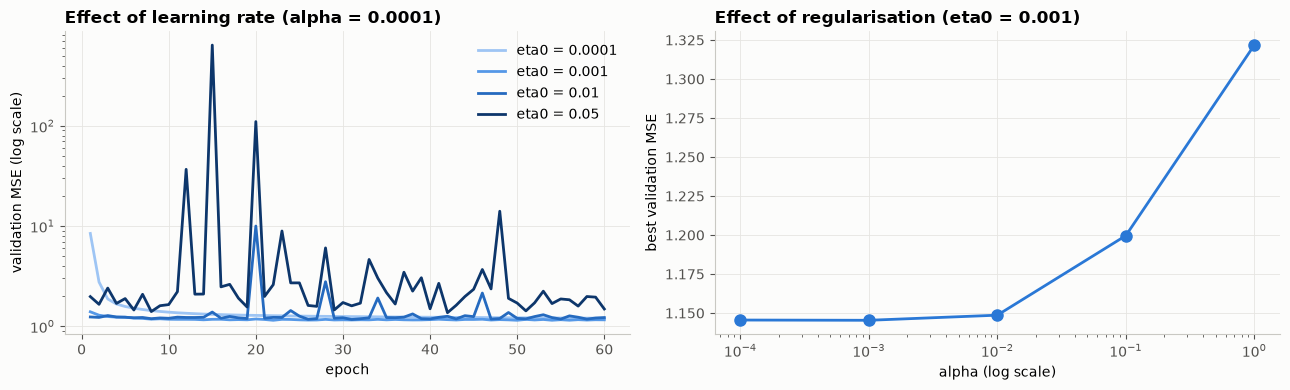

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for eta0, col in zip([0.0001, 0.001, 0.01, 0.05], ["#9ec5f4", "#5598e7", "#256abf", "#0d366b"]):
    _, _, vh = train_sgd(Xf, yf, Xv, yv, eta0, 0.0001, epochs=60)
    axes[0].plot(range(1, 61), vh[1:], color=col, lw=2, label=f"eta0 = {eta0}")
axes[0].set_yscale("log")
axes[0].set(title="Effect of learning rate (alpha = 0.0001)", xlabel="epoch", ylabel="validation MSE (log scale)")
axes[0].legend(frameon=False)
best_eta = sgd_grid.loc[0, "eta0"]
a = sgd_grid[sgd_grid["eta0"] == best_eta].sort_values("alpha")
axes[1].plot(a["alpha"], a["best val MSE"], marker="o", ms=8, lw=2, color=BLUE); axes[1].set_xscale("log")
axes[1].set(title=f"Effect of regularisation (eta0 = {best_eta})", xlabel="alpha (log scale)", ylabel="best validation MSE")
for ax in axes: left_title(ax)
plt.tight_layout(); plt.show()

**How each hyperparameter changed the loss:**
* **Learning rate.** `eta0 = 0.001` was best (validation MSE **1.1454**). With `0.0001` the steps are tiny: after
  one epoch the MSE is still **8.43**, and even after 60 epochs it only reaches about 1.20. With `0.01` the model
  learns fastest (1.24 after one epoch) but settles higher (best 1.1657) because the big steps keep overshooting.
  With `0.05` it is unstable and never gets below about 1.33.
* **Regularisation.** `alpha` from 0.0001 to 0.01 gives almost the same loss (1.1454 to 1.1486). Stronger penalties
  hurt: 0.1 gives 1.1996 and 1.0 gives 1.3217, because the weights are shrunk too far towards zero and the model
  underfits.
* **Epochs.** At `eta0 = 0.001`, validation MSE kept improving until epoch **50**, so that is what I use.

### Loss curve: train and test MSE per epoch with the chosen settings

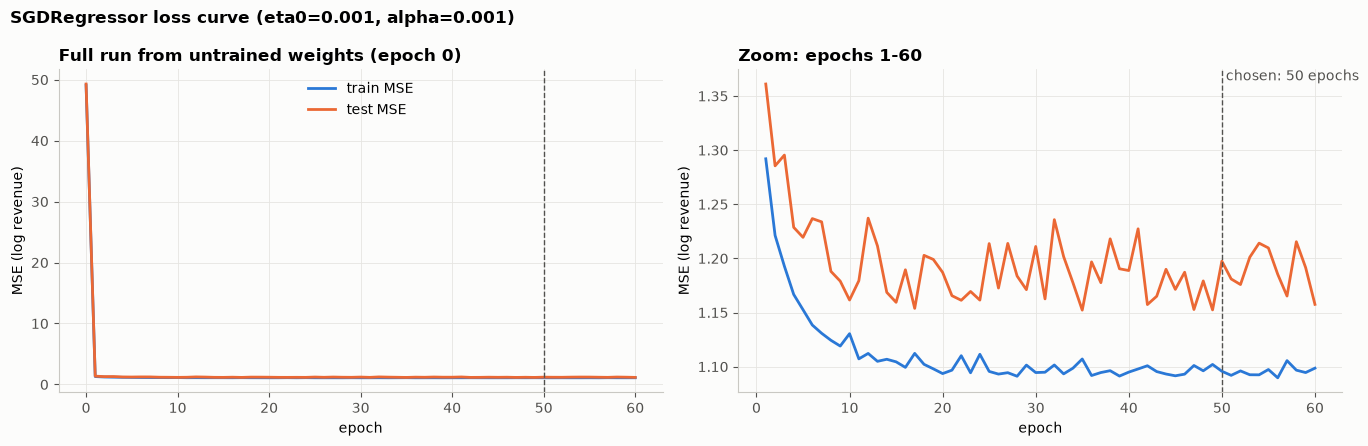

epoch 0: train 49.107 / test 49.290 | epoch 1: train 1.292 / test 1.361 | epoch 60: train 1.099 / test 1.158


In [15]:
BEST_ETA, BEST_ALPHA = float(sgd_grid.loc[0, "eta0"]), float(sgd_grid.loc[0, "alpha"])
BEST_EPOCHS, EPOCHS = int(sgd_grid.loc[0, "best epoch"]), 60
_, train_hist, test_hist = train_sgd(Xtr_s, y_train.to_numpy(), Xte_s, y_test.to_numpy(), BEST_ETA, BEST_ALPHA, EPOCHS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ep = np.arange(0, EPOCHS + 1)
for ax, start, title in [(axes[0], 0, "Full run from untrained weights (epoch 0)"), (axes[1], 1, "Zoom: epochs 1-60")]:
    ax.plot(ep[start:], train_hist[start:], color=BLUE, lw=2, label="train MSE")
    ax.plot(ep[start:], test_hist[start:], color=ORANGE, lw=2, label="test MSE")
    ax.axvline(BEST_EPOCHS, color=MUTED, lw=1, ls="--")
    ax.set(title=title, xlabel="epoch", ylabel="MSE (log revenue)"); left_title(ax)
axes[1].text(BEST_EPOCHS, axes[1].get_ylim()[1], f" chosen: {BEST_EPOCHS} epochs", color=MUTED, va="top")
axes[0].legend(frameon=False)
fig.suptitle(f"SGDRegressor loss curve (eta0={BEST_ETA}, alpha={BEST_ALPHA})", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"epoch 0: train {train_hist[0]:.3f} / test {test_hist[0]:.3f} | epoch 1: train {train_hist[1]:.3f} / test {test_hist[1]:.3f} | "
      f"epoch 60: train {train_hist[-1]:.3f} / test {test_hist[-1]:.3f}")

**Reading the curve.** At epoch 0 every weight is zero, so the model predicts a log revenue of 0 and the MSE is
about **49**. One epoch (5,487 small steps) brings it down to **1.29** train / **1.36** test. Over the next ~20
epochs, train MSE keeps falling to about **1.10** and then flattens. Test MSE follows the same path but stays
higher and bounces between about 1.15 and 1.24, because a constant learning rate keeps taking steps of the same
size. After 60 epochs: **1.099** train and **1.158** test. The gap is small, so the model **is not overfitting**.
Its limit is that it is a straight line (underfitting), not the amount of training.

## 8. Models 2-4: closed-form linear regression, decision tree, random forest
`LinearRegression` solves least squares exactly (no learning rate), so it is the reference point for SGD. For the
two tree models I tuned depth, leaf size, and for the forest the number of trees and features per split, all on
the same validation set.

In [16]:
def val_mse(model):
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)]).fit(X_fit, y_fit)
    return mean_squared_error(y_fit, pipe.predict(X_fit)), mean_squared_error(y_val, pipe.predict(X_val))

rows = []
for depth in [3, 4, 5, 6, 8, 10, None]:
    for leaf in [1, 20, 50, 100]:
        t, v = val_mse(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=SEED))
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "fit MSE": t, "val MSE": v})
dt_grid = pd.DataFrame(rows).sort_values("val MSE").reset_index(drop=True)
dt_grid.head(8).round({"fit MSE": 4, "val MSE": 4})

,max_depth,min_samples_leaf,fit MSE,val MSE
0,NaN,50,1.1261,1.2702
1,10.0,50,1.1261,1.2702
2,8.0,50,1.1263,1.2708
3,5.0,100,1.2056,1.2781
4,6.0,100,1.1948,1.2784
5,6.0,50,1.1506,1.2788
6,10.0,100,1.1920,1.2788
7,NaN,100,1.1920,1.2788


In [17]:
rows = []
for n in [100, 300]:
    for depth in [6, 10, 16, None]:
        for leaf in [3, 10, 30]:
            for mf in [0.33, 0.6, 1.0]:
                t, v = val_mse(RandomForestRegressor(n_estimators=n, max_depth=depth, min_samples_leaf=leaf,
                                                     max_features=mf, n_jobs=-1, random_state=SEED))
                rows.append({"n_estimators": n, "max_depth": depth, "min_samples_leaf": leaf,
                             "max_features": mf, "fit MSE": t, "val MSE": v})
rf_grid = pd.DataFrame(rows).sort_values("val MSE").reset_index(drop=True)
print(f"{len(rf_grid)} forests tried")
rf_grid.head(8).round({"fit MSE": 4, "val MSE": 4})

72 forests tried


,n_estimators,max_depth,min_samples_leaf,max_features,fit MSE,val MSE
0,300,16.0,3,0.33,0.6704,1.1058
1,100,16.0,3,0.33,0.6734,1.1146
2,300,NaN,3,0.33,0.6274,1.1157
3,300,16.0,3,0.60,0.6078,1.1216
4,100,16.0,3,0.60,0.6085,1.1238
5,100,NaN,3,0.33,0.6287,1.1241
6,300,10.0,3,0.60,0.7895,1.1271
7,300,10.0,3,0.33,0.8344,1.1276


**Decision tree.** The best tree needs at least **50 businesses per leaf** (validation MSE 1.2702). Depth hardly
matters once leaves are that large (depth 10 and unlimited depth give the same result). With small leaves, a single
tree memorises individual businesses, and revenue is far too noisy for that to generalise.

**Random forest.** The best of the **72** forests uses **300 trees, max depth 16, min 3 businesses per leaf, and a third
of the features at each split** (validation MSE **1.1058**). Using only a third of the features makes the trees
more different from each other, and averaging different trees cancels more noise. 300 trees beat 100 by a little
(1.1058 vs 1.1146).

## 9. Comparison of the four models on the same test set
Each model is retrained on the whole training set (fit + validation) with its chosen hyperparameters and scored
**once** on the test set. All four use the same preprocessing. *Typical error (×)* is e^RMSE: the factor by which a
prediction is typically too high or too low.

In [18]:
def opt_int(v):
    return None if pd.isna(v) else int(v)

dt, rf = dt_grid.loc[0], rf_grid.loc[0]
candidates = {
    "SGDRegressor (gradient descent)": SGDRegressor(learning_rate="constant", eta0=BEST_ETA, penalty="l2", alpha=BEST_ALPHA,
                                                    max_iter=BEST_EPOCHS, tol=None, random_state=SEED),
    "LinearRegression (closed form)": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=opt_int(dt["max_depth"]),
                                                   min_samples_leaf=int(dt["min_samples_leaf"]), random_state=SEED),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=int(rf["n_estimators"]), max_depth=opt_int(rf["max_depth"]),
                                                   min_samples_leaf=int(rf["min_samples_leaf"]),
                                                   max_features=float(rf["max_features"]), n_jobs=-1, random_state=SEED),
}
fitted, rows = {}, []
for name, model in candidates.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", model)]).fit(X_train, y_train)
    fitted[name] = pipe
    p_tr, p_te = pipe.predict(X_train), pipe.predict(X_test)
    rmse = mean_squared_error(y_test, p_te) ** 0.5
    rows.append({"model": name, "train MSE": mean_squared_error(y_train, p_tr), "test MSE": mean_squared_error(y_test, p_te),
                 "test RMSE": rmse, "typical error (x)": np.exp(rmse), "test R²": r2_score(y_test, p_te)})
comparison = pd.DataFrame(rows).sort_values("test MSE").reset_index(drop=True)
baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
BEST_NAME = comparison.loc[0, "model"]
print(f"Baseline (always predict the average log revenue): test MSE = {baseline:.4f}")
print(f"Best model (lowest test MSE): {BEST_NAME}")
comparison.round(4)

Baseline (always predict the average log revenue): test MSE = 1.6759
Best model (lowest test MSE): RandomForestRegressor


,model,train MSE,test MSE,test RMSE,typical error (x),test R²
0,RandomForestRegressor,0.6850,1.0782,1.0384,2.8246,0.3566
1,SGDRegressor (gradient descent),1.1089,1.1624,1.0781,2.9392,0.3064
2,LinearRegression (closed form),1.0877,1.1864,1.0892,2.9720,0.2921
3,DecisionTreeRegressor,1.1303,1.2390,1.1131,3.0438,0.2607


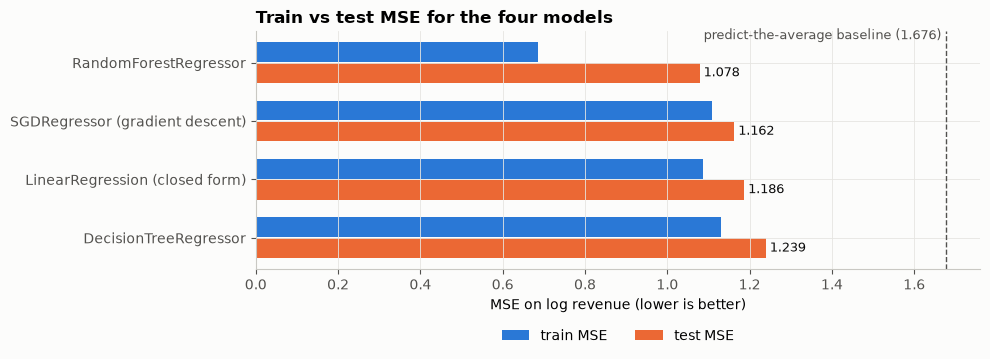

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
order = comparison.sort_values("test MSE", ascending=False); yy = np.arange(len(order))
ax.barh(yy + 0.18, order["train MSE"], height=0.34, color=BLUE, label="train MSE")
ax.barh(yy - 0.18, order["test MSE"], height=0.34, color=ORANGE, label="test MSE")
for i, te in enumerate(order["test MSE"]): ax.text(te + 0.01, i - 0.18, f"{te:.3f}", va="center", color=INK, fontsize=9)
ax.axvline(baseline, color=MUTED, ls="--", lw=1)
ax.text(baseline - 0.01, len(order) - 0.6, f"predict-the-average baseline ({baseline:.3f})", color=MUTED, fontsize=9, ha="right")
ax.set_yticks(yy, order["model"]); ax.set_xlabel("MSE on log revenue (lower is better)")
ax.set_title("Train vs test MSE for the four models"); left_title(ax)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2); plt.tight_layout(); plt.show()

**The best model is the `RandomForestRegressor`, chosen because it has the lowest test MSE: 1.0782.** That is a
test RMSE of 1.04 in log units, so a prediction is typically within a factor of about **2.8** of the real revenue,
and it explains **36%** of the variation (R² 0.357). Always guessing the average would give 1.6759, so the forest
reduces the error by **36%**. The others scored: SGD 1.1624, closed-form linear regression 1.1864, decision tree 1.2390.

**How the dataset shaped each model:**
* **The two linear models are close** because they fit the same kind of equation. SGD scores slightly better on
  test than the exact solution (1.162 vs 1.186) while being slightly worse on train (1.109 vs 1.088). The exact
  solution fits every one of the 52 columns perfectly to the training data, including states with as few as
  31 businesses (Nasarawa). SGD's L2 penalty and limited number of epochs hold the weights back, which generalises a
  little better.
* **The single decision tree is the weakest** (1.239). Survey revenue is noisy, and a single tree commits to hard
  thresholds that don't hold on new households.
* **The random forest is best** because it combines what both lack: it captures non-linear patterns (how the effect
  of education or business age differs by state and sector) and averages 300 trees to cancel noise. It still has
  a clear train/test gap (0.685 vs 1.078), meaning it memorises part of the training data. That is normal for
  forests, and it is why I judge every model on test MSE only.

**Why this choice fits the problem.** A lender sizing loans needs the most accurate estimate available, and this
data has non-linear, location-dependent patterns and a lot of noise. The forest handles both better than a straight
line, and it still answers an API request in milliseconds.

## 10. Scatter plots: the most correlated feature, before and after a fitted line
The feature most correlated with log revenue is `survey_year` (r = 0.255). It has two values, so the points form
two columns. I spread them sideways slightly (jitter) to show how dense each one is.

Feature most correlated with log revenue: survey_year (r = 0.255)


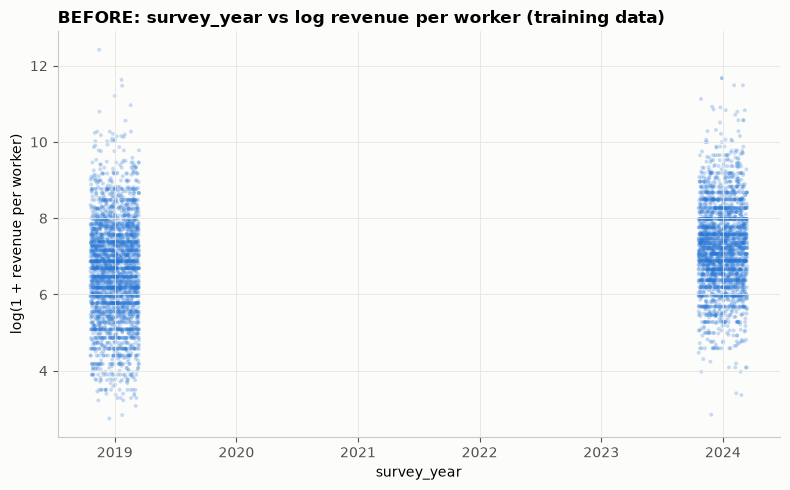

In [20]:
top = corr["log_revenue"].drop("log_revenue").abs().idxmax()
print(f"Feature most correlated with log revenue: {top} (r = {corr.loc[top, 'log_revenue']:.3f})")
x = train[top].to_numpy(dtype=float)
rng = np.random.default_rng(SEED)
spread = (x.max() - x.min()) or 1
jitter = rng.uniform(-0.04, 0.04, len(x)) * spread if train[top].nunique() <= 10 else 0
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x + jitter, y_train, s=8, alpha=0.25, color=BLUE, edgecolors="none")
ax.set(title=f"BEFORE: {top} vs log revenue per worker (training data)", xlabel=top, ylabel="log(1 + revenue per worker)")
left_title(ax); plt.tight_layout(); plt.show()

**Before.** Both years cover almost the same range (about 3 to 12 in log revenue), but the 2024 column sits
visibly higher. The overlap is large, which is why one feature alone can't predict well.

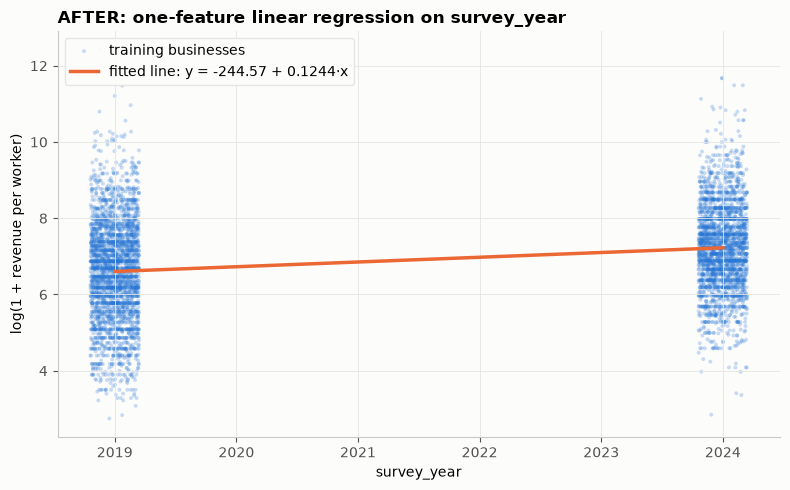

One-feature model on test: MSE 1.5462, R² 0.077


In [21]:
one = LinearRegression().fit(train[[top]], y_train)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x + jitter, y_train, s=8, alpha=0.25, color=BLUE, edgecolors="none", label="training businesses")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, one.predict(pd.DataFrame({top: xs})), color=ORANGE, lw=2.5,
        label=f"fitted line: y = {one.intercept_:.2f} + {one.coef_[0]:.4f}·x")
ax.set(title=f"AFTER: one-feature linear regression on {top}", xlabel=top, ylabel="log(1 + revenue per worker)")
left_title(ax); ax.legend(frameon=True, framealpha=0.95, facecolor="#fcfcfb", edgecolor="#e6e5e1", loc="upper left")
plt.tight_layout(); plt.show()
p1 = one.predict(test[[top]])
print(f"One-feature model on test: MSE {mean_squared_error(y_test, p1):.4f}, R² {r2_score(y_test, p1):.3f}")

**After.** The one-feature linear regression is **log revenue = −244.57 + 0.1244 × year**. With only two years in
the data the line simply joins the two group averages. A slope of 0.1244 per year over the 5 years between rounds
means revenue per worker about **e^(0.1244×5) ≈ 1.86 times** higher in 2024, which matches the jump in medians from
$772 to $1,365 (×1.77). On its own this feature reaches a test MSE of **1.5462** (R² 0.077), barely better than the
1.6759 baseline. The other 11 features bring the forest down to 1.0782.

## 11. Which features matter most for the best model
The one-hot columns of each text input are added back together, so `state` shows as one bar.

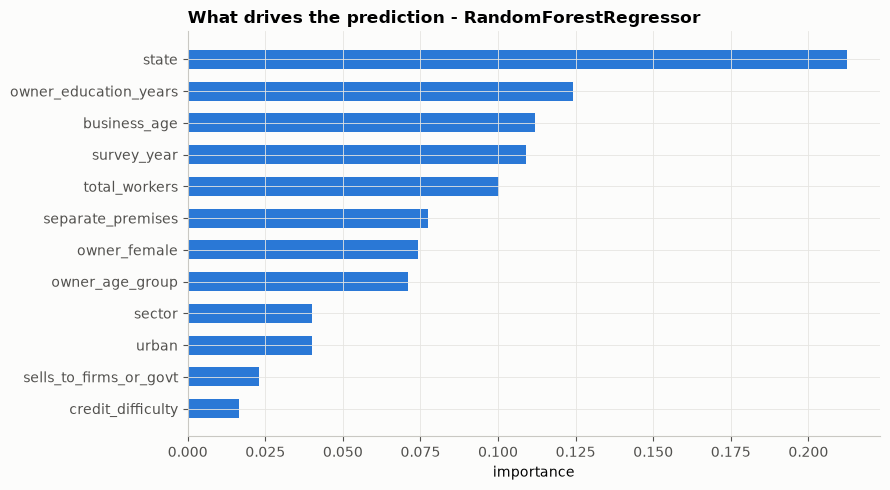

state                     0.212
owner_education_years     0.124
business_age              0.112
survey_year               0.109
total_workers             0.100
separate_premises         0.077
owner_female              0.074
owner_age_group           0.071
sector                    0.040
urban                     0.040
sells_to_firms_or_govt    0.023
credit_difficulty         0.016
dtype: float64

In [22]:
best = fitted[BEST_NAME]; model = best.named_steps["model"]
cols = [n.split("__")[-1] for n in best.named_steps["prep"].get_feature_names_out()]
values = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_)
imp = pd.Series(values, index=cols)
grouped = {c: imp[[k for k in imp.index if k.startswith(c + "_")]].sum() for c in CATEGORICAL}  # add up one-hot columns
imp = pd.concat([imp[NUMERIC], pd.Series(grouped)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set(title=f"What drives the prediction - {BEST_NAME}",
       xlabel="importance" if hasattr(model, "feature_importances_") else "sum of |coefficients| (standardised)")
left_title(ax); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

**Reading it.** **State** matters most (0.21). Where a business operates in Nigeria changes its revenue more than any
single trait of the owner, which is why the straight-line correlations looked weak. Next come **owner education**
(0.12), **business age** (0.11), **survey year** (0.11) and **number of workers** (0.10). Separate premises, owner
gender and age group each add about 0.07. Sector, urban/rural, selling to firms and credit difficulty add the
least. They still help a little, and they are fields the lender will ask about anyway.

## 12. Save the best model with its preprocessing
One file, `API/best_model.pkl`, saved with `joblib`. It holds the full `Pipeline` (filling missing values,
scaling, one-hot encoding and the random forest), plus the information the API needs: the input names, the
valid ranges and categories, and a note that the output is log revenue. **No data rows are stored in it**, because
the licence does not allow them to be shared. The cleaned training and test rows are written to the local
`data/` folder instead (ignored by git); the API's `/retrain` route reads them from a private Render Secret File.

In [23]:
API_DIR = Path("..") / "API"
bundle = {
    "model": best,                                     # preprocessing + model in one Pipeline
    "model_name": BEST_NAME,
    "features": FEATURES,
    "numeric": NUMERIC,
    "categorical": CATEGORICAL,
    "target": TARGET,
    "target_transform": "log1p",                       # predictions must go through expm1 to become PPP $
    "test_mse": float(comparison.loc[0, "test MSE"]),
    "numeric_ranges": {c: (float(data[c].min()), float(data[c].max())) for c in NUMERIC},
    "states": sorted(data["state"].unique().tolist()),
    "sectors": sorted(data["sector"].unique().tolist()),
    "urban_values": sorted(data["urban"].unique().tolist()),
}
# No data rows are stored in this file: the World Bank licence does not allow sharing them.
joblib.dump(bundle, API_DIR / "best_model.pkl", compress=3)
print(f"Saved {BEST_NAME} to {API_DIR / 'best_model.pkl'} ({(API_DIR / 'best_model.pkl').stat().st_size / 1e6:.2f} MB)")

# The API's /retrain route refits the forest on "original training rows + new rows", so it needs the
# cleaned rows. They are written to data/ (ignored by git) and uploaded to Render privately as
# Secret Files - never to the public repository.
train[FEATURES + [TARGET]].to_csv(Path("data") / "train_clean.csv", index=False)
test[FEATURES + [TARGET]].to_csv(Path("data") / "test_clean.csv", index=False)
print(f"Wrote data/train_clean.csv ({len(train):,} rows) and data/test_clean.csv ({len(test):,} rows) - local only")
pd.DataFrame(bundle["numeric_ranges"], index=["min", "max"]).T

Saved RandomForestRegressor to ..\API\best_model.pkl (8.35 MB)
Wrote data/train_clean.csv (5,487 rows) and data/test_clean.csv (1,404 rows) - local only


,min,max
survey_year,2019.0,2024.0
total_workers,1.0,56.0
business_age,1.0,77.0
owner_education_years,0.0,18.0
owner_age_group,1.0,6.0
owner_female,0.0,1.0
separate_premises,0.0,1.0
sells_to_firms_or_govt,0.0,1.0
credit_difficulty,0.0,1.0


These ranges become the API's validation rules. For example, workers must be 1-56, business age 1-77 years,
education 0-18 years, and the year 2019-2024. The model has never seen values outside them, so the API returns an
error instead of a made-up number.

## 13. Load the saved model and predict one row of the test set
This is the function the API reuses. It loads the file from disk, predicts the log revenue for one business, and
converts it back to PPP dollars with `expm1` (the inverse of `log1p`).

In [24]:
def predict_revenue_per_worker(row: dict, model_path=API_DIR / "best_model.pkl") -> float:
    """Load the saved model from disk and predict monthly revenue per worker (PPP $) for ONE business."""
    saved = joblib.load(model_path)
    frame = pd.DataFrame([row], columns=saved["features"])
    log_pred = float(saved["model"].predict(frame)[0])
    return round(float(np.expm1(log_pred)), 2)          # undo log(1 + y)

row = X_test.iloc[0].to_dict()
print("Input (first business in the test set):")
for k, v in row.items(): print(f"  {k:<24} {v}")
print(f"\nPredicted revenue per worker: ${predict_revenue_per_worker(row):,.2f} PPP per month")
print(f"Actual revenue per worker:    ${test[TARGET].iloc[0]:,.2f} PPP per month")

Input (first business in the test set):
  survey_year              2019
  total_workers            5.0
  business_age             15.0
  owner_education_years    18.0
  owner_age_group          5.0
  owner_female             0.0
  separate_premises        1.0
  sells_to_firms_or_govt   0.0
  credit_difficulty        1.0
  state                    Abia
  sector                   Services
  urban                    Rural



Predicted revenue per worker: $2,323.42 PPP per month
Actual revenue per worker:    $1,605.91 PPP per month


**Result.** For the first test business (a rural services business in Abia with 5 workers, 15 years old, owner with
18 years of education, 2019), the saved model predicts **$2,323** per worker per month and the survey reports
**$1,606**. The prediction is 1.45 times too high, which is well inside the model's typical factor of 2.8.

## 14. Summary
| | |
|---|---|
| Best model | Random forest (300 trees, depth ≤ 16, ≥ 3 per leaf, ⅓ of features per split) |
| Test MSE (log revenue) | **1.0782**, against 1.6759 for always guessing the average (−36%) |
| Typical error | about ×2.8 (test RMSE 1.04 in log units), R² 0.36 |
| Is the loss high or low? | Moderate. A ×2.8 typical error is too wide to set an exact loan amount for one business, but good enough to place a business in a revenue band (micro, small, medium) and to rank applicants. That is how a lender would first use it. |
| How to reduce it | Add the household's other income and assets (available in the full GHS-Panel files), the business's monthly costs measured separately from revenue, and mobile-money transaction history. Also try gradient boosting, and train on more survey rounds. |
| Tuning that mattered | Learning rate (0.001 best; 0.0001 too slow, 0.05 unstable); L2 helps up to 0.01 and hurts at 0.1 and above; trees need large leaves (50+) because survey revenue is noisy. |